In [1]:
print("hello")

hello


In [2]:
import pandas as pd

ModuleNotFoundError: No module named 'pandas'

In [10]:
%pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 13.4 MB/s  0:00:00eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [9]:
%pip install numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 1.2 MB/s  0:00:04 eta 0:00:010m
Note: you may need to restart the kernel to use updated packages.


In [11]:
%pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 12.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 12.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 12.6 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


Matplotlib is building the font cache; this may take a moment.


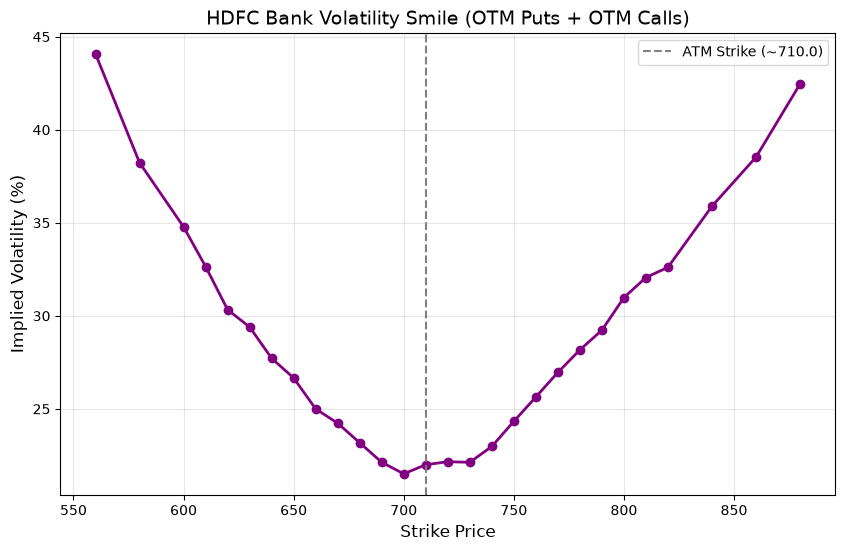

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the NSE option chain (skiprows=1 bypasses the blank header row)
df = pd.read_csv('option-chain-ED-HDFCBANK-27-Oct-2026.csv', skiprows=1)

# Clean up column names by stripping random spaces
df.columns = df.columns.str.strip()

# 2. Clean the data 
# NSE data uses '-' for empty values. We force these to NaN (Not a Number)
df['IV'] = pd.to_numeric(df['IV'], errors='coerce')      # Call IV
df['IV.1'] = pd.to_numeric(df['IV.1'], errors='coerce')  # Put IV
df['STRIKE'] = pd.to_numeric(df['STRIKE'], errors='coerce')
df['LTP'] = pd.to_numeric(df['LTP'], errors='coerce')      # Call Last Traded Price
df['LTP.1'] = pd.to_numeric(df['LTP.1'], errors='coerce')  # Put Last Traded Price

# Drop rows without a valid Strike price
df = df.dropna(subset=['STRIKE'])

# 3. Find the At-The-Money (ATM) Strike
# ATM is exactly where Call prices and Put prices are closest to each other
df['price_diff'] = abs(df['LTP'] - df['LTP.1'])
atm_strike = df.loc[df['price_diff'].idxmin(), 'STRIKE']

# 4. The Stitching Trick
# If Strike < ATM: Use Put IV (IV.1)
# If Strike >= ATM: Use Call IV (IV)
df['OTM_IV'] = np.where(df['STRIKE'] < atm_strike, df['IV.1'], df['IV'])

# Clean up any missing IV points before plotting
plot_df = df.dropna(subset=['OTM_IV']).sort_values('STRIKE')

# 5. Plot the Volatility Smile
plt.figure(figsize=(10, 6))
plt.plot(plot_df['STRIKE'], plot_df['OTM_IV'], marker='o', linestyle='-', color='purple', linewidth=2)

# Draw a vertical line right at the current stock price
plt.axvline(x=atm_strike, color='gray', linestyle='--', label=f'ATM Strike (~{atm_strike})')

plt.title('HDFC Bank Volatility Smile (OTM Puts + OTM Calls)', fontsize=14)
plt.xlabel('Strike Price', fontsize=12)













plt.ylabel('Implied Volatility (%)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [4]:
import requests
import time
from datetime import datetime

# 1. Initialize a session to persist cookies across requests
session = requests.Session()

# 2. Spoof a standard desktop browser
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/avif,image/webp,*/*;q=0.8",
    "Accept-Language": "en-US,en;q=0.5",
    "Accept-Encoding": "gzip, deflate, br",
    "Connection": "keep-alive"
}
session.headers.update(headers)

def fetch_bhavcopy(date_str):
    """
    date_str format: '16OCT2026'
    """
    # Step 1: The Cookie Harvest
    # Hit the main NSE homepage first to generate valid session cookies
    home_url = "https://www.nseindia.com"
    try:
        session.get(home_url, timeout=10)
    except requests.exceptions.RequestException as e:
        print(f"Failed to fetch cookies: {e}")
        return None

    # Step 2: The Archive Request
    # NSE F&O Bhavcopy URL structure:
    year = date_str[-4:]
    month = date_str[2:5].upper()
    archive_url = f"https://archives.nseindia.com/content/historical/DERIVATIVES/{year}/{month}/fo{date_str}bhav.csv.zip"
    
    response = session.get(archive_url, timeout=10)
    
    if response.status_code == 200:
        with open(f"fo{date_str}bhav.csv.zip", 'wb') as file:
            file.write(response.content)
        print(f"Successfully downloaded {date_str}")
        return True
    else:
        print(f"Failed for {date_str} - Status Code: {response.status_code}")
        return False

# Example execution for a single day
fetch_bhavcopy("16OCT2026")

Failed for 16OCT2026 - Status Code: 404


False

In [3]:
%pip install requests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [requests]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import requests
import time
from datetime import datetime

# 1. Initialize a session to persist cookies
session = requests.Session()

# 2. Spoof a standard desktop browser (NSE blocks default Python user-agents)
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36",
    "Accept": "text/html,application/xhtml+xml,application/xml",
    "Accept-Language": "en-US,en;q=0.5",
    "Connection": "keep-alive"
}
session.headers.update(headers)

def fetch_udiff_bhavcopy(date_str):
    """
    date_str format: 'YYYYMMDD' (e.g., '20261016')
    """
    # Step 1: Hit the NSE homepage to harvest the required WAF session cookies
    home_url = "https://www.nseindia.com"
    try:
        session.get(home_url, timeout=10)
    except requests.exceptions.RequestException as e:
        print(f"Failed to fetch cookies: {e}")
        return False

    # Step 2: Request the new UDiFF Derivatives (FO) archive file
    # Format: BhavCopy_NSE_FO_0_0_0_YYYYMMDD_F_0000.csv.zip
    file_name = f"BhavCopy_NSE_FO_0_0_0_{date_str}_F_0000.csv.zip"
    archive_url = f"https://nsearchives.nseindia.com/content/fo/{file_name}"
    
    response = session.get(archive_url, timeout=10)
    
    if response.status_code == 200:
        with open(file_name, 'wb') as file:
            file.write(response.content)
        print(f"Successfully downloaded {date_str} UDiFF Bhavcopy.")
        return True
    else:
        print(f"Failed for {date_str} - Status Code: {response.status_code}")
        return False

# Execute for October 16, 2026
fetch_udiff_bhavcopy("20261016")

Successfully downloaded 20261016 UDiFF Bhavcopy.


True

In [ ]:
import pandas as pd
import numpy as np 

file_name = "BhavCopy_NSE_FO_0_0_0_20261016_F_0000.csv.zip"
df = pd.read_csv(file_name, compression='zip')



In [ ]:
import pandas as pd
import numpy as np

# 1. Load the zipped UDiFF CSV directly into memory
file_name = "BhavCopy_NSE_FO_0_0_0_20261016_F_0000.csv.zip"
df = pd.read_csv(file_name, compression='zip')

# 2. Isolate NIFTY Optionsa
# OptnTp contains 'CE' (Call) or 'PE' (Put)
nifty_opts = df[(df['TckrSymb'] == 'NIFTY') & (df['OptnTp'].isin(['CE', 'PE']))].copy()

# 3. Calculate Time to Maturity (T) in Trading Days
trad_dates = pd.to_datetime(nifty_opts['TradDt']).values.astype('datetime64[D]')
xpry_dates = pd.to_datetime(nifty_opts['XpryDt']).values.astype('datetime64[D]')

# Explicit NSE holidays (Add remaining 2026/2027 holidays to this array)
nse_holidays = np.array([
    '2026-10-20', # Dussehra / Example
    '2026-11-09', # Diwali
    '2026-12-25'  # Christmas
], dtype='datetime64[D]')

nifty_opts['trading_days'] = np.busday_count(trad_dates, xpry_dates, holidays=nse_holidays)
nifty_opts['T'] = nifty_opts['trading_days'] / 252.0

# 4. The Vega Collapse Filter: Drop contracts expiring in < 2 days
nifty_opts = nifty_opts[nifty_opts['T'] >= (2/252.0)].copy()

# 5. Financial Transformations (r, F, k)
# We apply the 91-day T-Bill flat-curve assumption (e.g., 6.5%) to save weekend build time
r_proxy = 0.065 

# Forward Price: F = S * e^(rT)
nifty_opts['F'] = nifty_opts['UndrlygPric'] * np.exp(r_proxy * nifty_opts['T'])

# Log-Moneyness: k = ln(K/F)
nifty_opts['k'] = np.log(nifty_opts['StrkPric'] / nifty_opts['F'])

# 6. Isolate the final clean schema required for Phase 3 (Black-Scholes Inversion)
clean_df = nifty_opts[['TradDt', 'XpryDt', 'StrkPric', 'OptnTp', 'SttlmPric', 'UndrlygPric', 'T', 'F', 'k']]

print(f"Cleaned contracts ready for IV calculation: {len(clean_df)}")
print(clean_df.head())

Cleaned contracts ready for IV calculation: 1674
           TradDt      XpryDt  StrkPric OptnTp  SttlmPric  UndrlygPric  \
29759  2026-10-16  2026-11-09   20650.0     PE       0.07     23146.15   
29760  2026-10-16  2026-11-09   20550.0     PE       0.04     23146.15   
29761  2026-10-16  2026-11-03   24800.0     PE    1587.16     23146.15   
29762  2026-10-16  2026-11-03   21750.0     PE      20.05     23146.15   
29763  2026-10-16  2026-10-27   25150.0     PE    1960.35     23146.15   

              T             F         k  
29759  0.059524  23235.877024 -0.117982  
29760  0.059524  23235.877024 -0.122837  
29761  0.043651  23211.915863  0.066178  
29762  0.043651  23211.915863 -0.065052  
29763  0.023810  23181.999156  0.081482  
